In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

In [21]:
# =====================================================================
# 1. DATA INGESTION & PREPROCESSING
# =====================================================================

def load_and_preprocess_data(file):

    df = pd.read_csv(file)

    print("--- Dataset Structural EDA ---")
    print(f"Dataset Shape: {df.shape}")
    print(f"Missing Values: {df.isnull().sum().sum()}")

    # Transform target: Quality >= 6 is "Good" (1), < 6 is "Bad" (0)
    df['target'] = (df['quality'] >= 6).astype(int)

    print("\nTarget Class Distribution:")
    print(df['target'].value_counts(normalize=True))

    # Separate design matrix and label
    X = df.drop(columns=['quality', 'target'])
    y = df['target']

    # Train/Test Split with stratification to preserve imbalanced class ratios
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Scale features (Critical step for SGD and SVC to prevent variance distortion)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Convert back to DataFrame for easier feature handling later
    X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
    X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

    return X_train_scaled, X_test_scaled, y_train, y_test

In [22]:
# =====================================================================
# 2. MODEL TUNING & ARCHITECTURE PIPELINE
# =====================================================================

def train_and_tune_models(X_train, y_train):
    """
    Defines hyperparameter grids and runs GridSearchCV across multiple frameworks.
    """
    models_config = {
        'RandomForest': {
            'model': RandomForestClassifier(random_state=42),
            'params': {
                'n_estimators':[50, 100, 200],
                'max_depth': [None, 10, 20],
                'min_samples_split': [2, 5]
            }
        },
        'SGDClassifier': {
            'model': SGDClassifier(random_state=42, max_iter=2000),
            'params': {
                'loss': ['hinge', 'log_loss'],  # hinge = Linear SVM, log_loss = LogReg
                'penalty': ['l2', 'l1'],
                'alpha': [0.0001, 0.001, 0.01]
            }
        },
        'SVC': {
            'model': SVC(random_state=42),
            'params': {
                'C': [0.1, 1, 10],
                'kernel': ['rbf', 'linear']
            }
        }
    }

    best_estimators = {}

    for name, config in models_config.items():
        print(f"\nTuning hyperparameters for {name}...")
        grid = GridSearchCV(
            estimator=config['model'],
            param_grid=config['params'],
            cv=5,
            scoring='f1_macro',
            n_jobs=-1
        )
        grid.fit(X_train, y_train)
        print(f"Best Parameters: {grid.best_params_}")
        best_estimators[name] = grid.best_estimator_

    return best_estimators

In [23]:
# =====================================================================
# 3. PERFORMANCE EVALUATION & VISUALISATION
# =====================================================================

def evaluate_and_compare(models, X_test, y_test):
    """
    Generates classification metrics and side-by-side confusion matrices.
    """
    performance_records = []
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for idx, (name, model) in enumerate(models.items()):
        y_pred = model.predict(X_test)

        # Calculate evaluation metrics
        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average='macro')

        performance_records.append({
            'Model': name,
            'Accuracy': acc,
            'Macro F1-Score': f1
        })

        # Print text metrics report
        print(f"\n==================== {name} Classification Report ====================")
        print(classification_report(y_test, y_pred, target_names=['Bad (<6)', 'Good (>=6)']))

        # Compute and plot confusion matrix
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
        axes[idx].set_title(f'{name} Confusion Matrix')
        axes[idx].set_xlabel('Predicted Label')
        axes[idx].set_ylabel('True Label')
        axes[idx].set_xticklabels(['Bad', 'Good'])
        axes[idx].set_yticklabels(['Bad', 'Good'])

    plt.tight_layout()
    plt.show()

    # Benchmarking summary frame
    perf_df = pd.DataFrame(performance_records)
    print("\n--- MODEL PERFORMANCE BENCHMARK ---")
    print(perf_df.to_string(index=False))

In [24]:
def plot_feature_importance(rf_model, feature_names):
    """
    Extracts and displays feature priority rankings from the Random Forest model.
    """
    importances = rf_model.feature_importances_
    indices = np.argsort(importances)[::-1]

    plt.figure(figsize=(10, 6))
    plt.title("Random Forest - Feature Importance Rankings", fontsize=14)

    sns.barplot(
        x=importances[indices],
        y=np.array(feature_names)[indices],      # Aligns the labels on the Y-axis
        hue=np.array(feature_names)[indices],    # Controls the color palette mapping
        palette="viridis",
        legend=False
    )

    plt.xlabel("Relative Importance Score")
    plt.ylabel("Physicochemical Properties")
    plt.tight_layout()
    plt.show()

In [25]:
X_tr, X_te, y_tr, y_te = load_and_preprocess_data("uci_wine_quality_red.csv")

--- Dataset Structural EDA ---
Dataset Shape: (1599, 12)
Missing Values: 0

Target Class Distribution:
target
1    0.561601
0    0.438399
Name: proportion, dtype: float64


In [ ]:

# 2. Run Optimization Grid Search
tuned_models = train_and_tune_models(X_tr, y_tr)


Tuning hyperparameters for RandomForest...
Best Parameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}

Tuning hyperparameters for SGDClassifier...
Best Parameters: {'alpha': 0.01, 'loss': 'log_loss', 'penalty': 'l2'}

Tuning hyperparameters for SVC...
Best Parameters: {'C': 10, 'kernel': 'linear'}



==================== RandomForest Classification Report ====================
              precision    recall  f1-score   support

    Bad (<6)       0.70      0.59      0.64       140
  Good (>=6)       0.71      0.81      0.76       180

    accuracy                           0.71       320
   macro avg       0.71      0.70      0.70       320
weighted avg       0.71      0.71      0.71       320


==================== SGDClassifier Classification Report ====================
              precision    recall  f1-score   support

    Bad (<6)       0.72      0.56      0.63       140
  Good (>=6)       0.71      0.83      0.77       180

    accuracy                           0.72       320
   macro avg       0.72      0.70      0.70       320
weighted avg       0.72      0.72      0.71       320


==================== SVC Classification Report ====================
              precision    recall  f1-score   support

    Bad (<6)       0.71      0.59      0.64       140
  Good (>=6

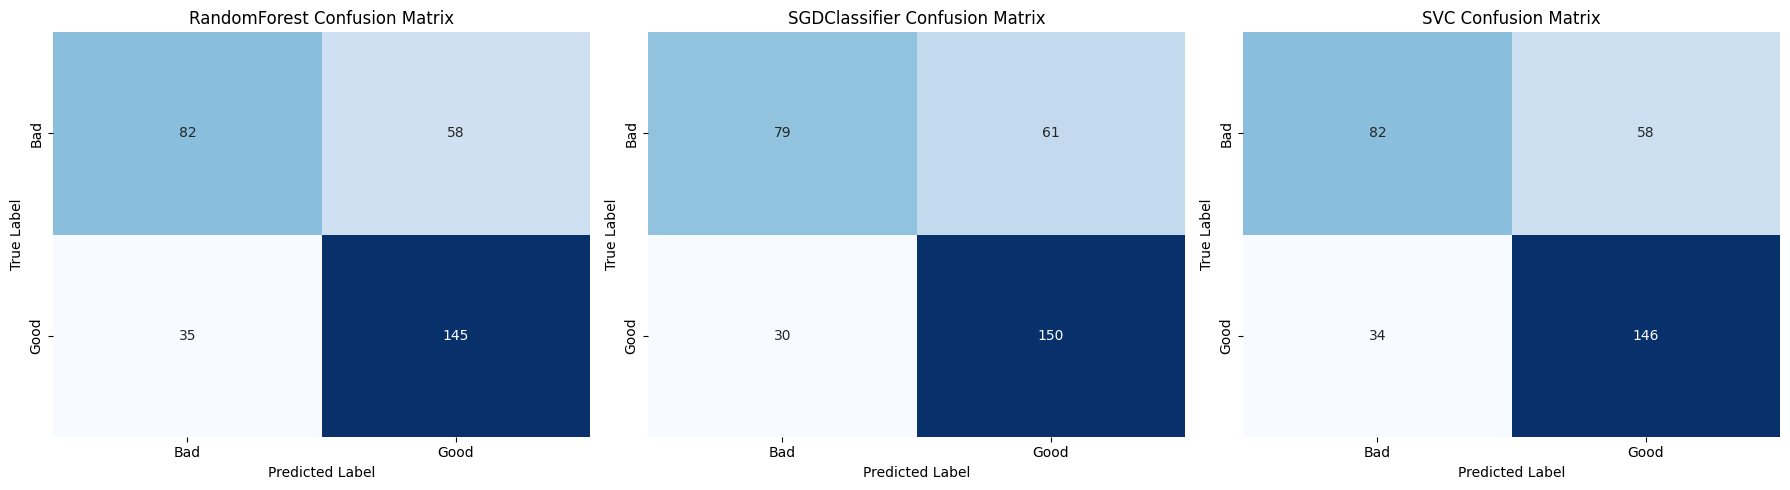


--- MODEL PERFORMANCE BENCHMARK ---
        Model  Accuracy  Macro F1-Score
 RandomForest  0.709375        0.697656
SGDClassifier  0.715625        0.700901
          SVC  0.712500        0.700521


In [ ]:
# 3. Graph Diagnostics and Compare Benchmarks
evaluate_and_compare(tuned_models, X_te, y_te)

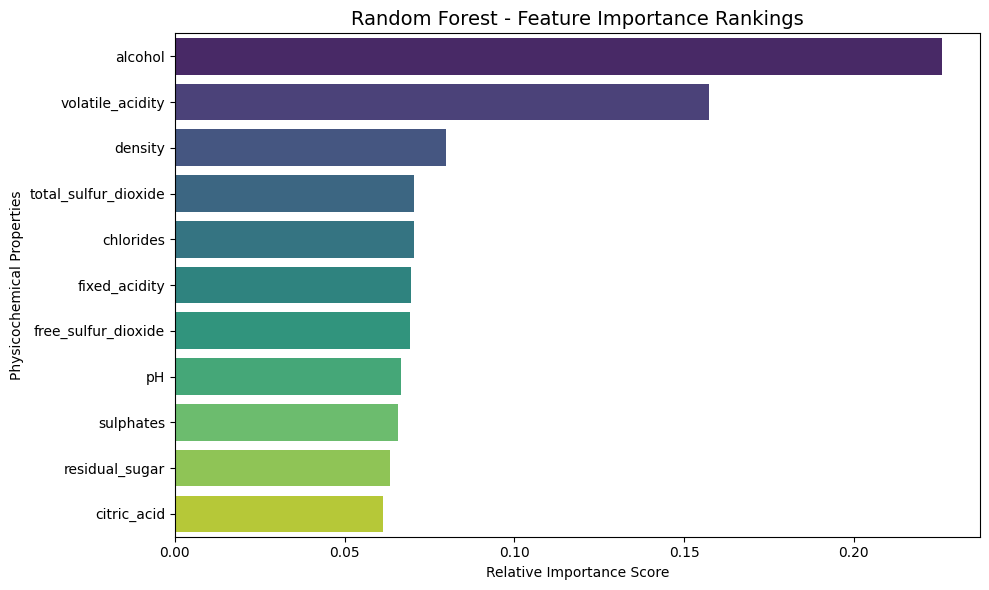

In [ ]:
# 4. Interpret Model Drivers
if 'RandomForest' in tuned_models:
    plot_feature_importance(tuned_models['RandomForest'], X_tr.columns)